# Análisis Exploratorio de Datos (EDA) y Visualización
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** A partir del dataset previamente analizado y libre de fugas de datos (`CTG_clean.csv`), este notebook analiza el comportamiento estadístico de las 21 variables clínicas y la distribución de la variable objetivo (`NSP`).

### Objetivos
1. Analizar las escalas y distribuciones de las variables predictivas para definir el preprocesamiento matemático de la matriz de características `X`.

2. Evaluar el balance de clases en el vector objetivo `y` (`NSP`) para establecer las métricas adecuadas de validación frente a las predicciones `y_hat`.

3. Identificar mediante correlaciones y visualizaciones las variables fisiológicas con mayor impacto en la detección de sufrimiento fetal.

In [2]:
# Importación de Librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Config para graficos
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
# Carga del DataSet
clean_data_path = '../data/processed/CTG_clean.csv'
df = pd.read_csv(clean_data_path)

display(df.head())
df.info()

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency,NSP
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   LB        2126 non-null   float64
 1   AC        2126 non-null   float64
 2   FM        2126 non-null   float64
 3   UC        2126 non-null   float64
 4   DL        2126 non-null   float64
 5   DS        2126 non-null   float64
 6   DP        2126 non-null   float64
 7   ASTV      2126 non-null   float64
 8   MSTV      2126 non-null   float64
 9   ALTV      2126 non-null   float64
 10  MLTV      2126 non-null   float64
 11  Width     2126 non-null   float64
 12  Min       2126 non-null   float64
 13  Max       2126 non-null   float64
 14  Nmax      2126 non-null   float64
 15  Nzeros    2126 non-null   float64
 16  Mode      2126 non-null   float64
 17  Mean      2126 non-null   float64
 18  Median    2126 non-null   float64
 19  Variance  2126 non-null   float64
 20  Tendency  2126 non-null   float64
 21  NS

In [4]:
# Cambio de tipo de variable de 'NSP' a enteros.
df['NSP'] = df['NSP'].astype(int)
df.info()
print(f"Dimensiones del dataset: {df.shape}")

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   LB        2126 non-null   float64
 1   AC        2126 non-null   float64
 2   FM        2126 non-null   float64
 3   UC        2126 non-null   float64
 4   DL        2126 non-null   float64
 5   DS        2126 non-null   float64
 6   DP        2126 non-null   float64
 7   ASTV      2126 non-null   float64
 8   MSTV      2126 non-null   float64
 9   ALTV      2126 non-null   float64
 10  MLTV      2126 non-null   float64
 11  Width     2126 non-null   float64
 12  Min       2126 non-null   float64
 13  Max       2126 non-null   float64
 14  Nmax      2126 non-null   float64
 15  Nzeros    2126 non-null   float64
 16  Mode      2126 non-null   float64
 17  Mean      2126 non-null   float64
 18  Median    2126 non-null   float64
 19  Variance  2126 non-null   float64
 20  Tendency  2126 non-null   float64
 21  NS

> **Conclusión de la Etapa 1:** 

> Se cargó con éxito el Dataset limpio y se convirtió la variable objetivo `NSP` a tipo numérico entero (`1, 2, 3`). Esto garantiza la compatibilidad de los tipos de datos con las operaciones algebraicas de nuestras futuras clases de clasificación.

### 2. Estadistica Descriptiva y Analisis de Escalas

In [5]:
# Nos quedamos solo con las caracteristicas (X)
df_features = df.drop(columns=['NSP'])

# Se calculan estadisticas clave y se tranpone la tabla 
resumen_stats = df_features.describe().T

# Se calcula el rango de cada caracteristica
resumen_stats['Rango'] = resumen_stats['max'] - resumen_stats['min']

print("--- Estadísticas Descriptivas (Variables Predictivas) ---")
display(resumen_stats[['min', 'mean', 'max', 'std', 'Rango']].round(4))

--- Estadísticas Descriptivas (Variables Predictivas) ---


,min,mean,max,std,Rango
LB,106.0,133.3039,160.0000,9.8408,54.0000
AC,0.0,0.0032,0.0193,0.0039,0.0193
FM,0.0,0.0095,0.4806,0.0467,0.4806
UC,0.0,0.0044,0.0149,0.0029,0.0149
DL,0.0,0.0019,0.0154,0.0030,0.0154
DS,0.0,0.0000,0.0014,0.0001,0.0014
DP,0.0,0.0002,0.0053,0.0006,0.0053
ASTV,12.0,46.9901,87.0000,17.1928,75.0000
MSTV,0.2,1.3328,7.0000,0.8832,6.8000
ALTV,0.0,9.8467,91.0000,18.3969,91.0000


> **Conclusión de la Etapa 2:** 

> El analisis descriptivo muestra una diferencia extrema en las escalas de la matriz `X` (p. ej., `LB` opera en cientos, mientras `AC` opera en milésimas). Esto justifica y hace **obligatoria** la implementación de una función de Estandarización para que los algoritmos de ML no se sesguen hacia las variables de mayor magnitud.

### 3. Distribución de la Variable Objetivo (Target `y`)

El vector objetivo `y` en nuestro problema está representado por la columna `NSP`. Antes de entrenar los modelos, es importante evaluar la proporción de pacientes en cada clase. 

En datasets médicos es común encontrar un **desbalance de clases** (muchos pacientes sanos y pocos casos patológicos). 



In [6]:
# Calculamos frecuencias absolutas y relativas
conteo = df['NSP'].value_counts().sort_index()
porcentajes = (df['NSP'].value_counts(normalize=True).sort_index() * 100).round(2)

distribucion_y = pd.DataFrame({
    'Pacientes (Conteo)': conteo,
    'Porcentaje (%)': porcentajes
})
distribucion_y.index = ['1 (Normal)', '2 (Sospechoso)', '3 (Patológico)']

print("--- Distribución de Clases (Vector y) ---")
display(distribucion_y)

--- Distribución de Clases (Vector y) ---


,Pacientes (Conteo),Porcentaje (%)
1 (Normal),1655,77.85
2 (Sospechoso),295,13.88
3 (Patológico),176,8.28


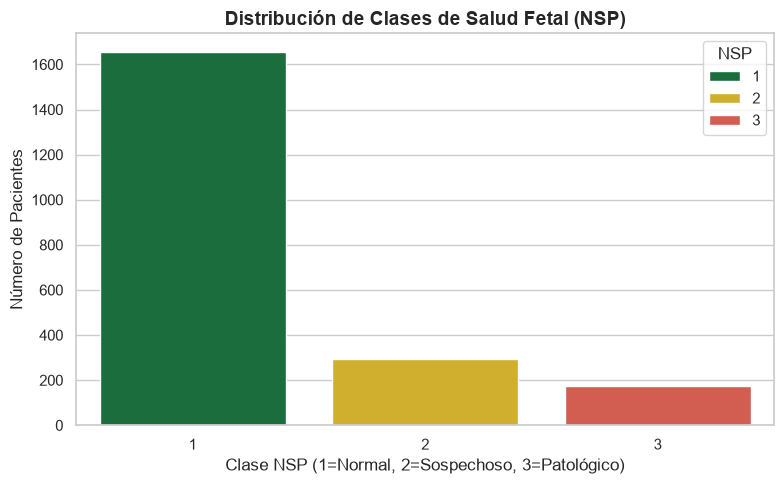

In [7]:
# Graficación de la Distribución Y
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='NSP', palette=["#0e7b3b", "#eabf12", '#e74c3c'], hue='NSP')

plt.title('Distribución de Clases de Salud Fetal (NSP)', fontsize=14, fontweight='bold')
plt.xlabel('Clase NSP (1=Normal, 2=Sospechoso, 3=Patológico)', fontsize=12)
plt.ylabel('Número de Pacientes', fontsize=12)

plt.tight_layout()
plt.show()

> **Conclusión de la Etapa 3:** 

> Se verifico un alto **desbalance de clases** (77.85% Normal vs. 8.28% Patológico). Debido a esto, la métrica de Exactitud (*Accuracy*) será engañosa durante el modelado. El desempeño real de los algoritmos deberá evaluarse prioritariamente mediante el **F1-Score**, **Recall** y el análisis de la **Matriz de Confusión**.

### Matriz de Correlación y Poder Predictivo

Para entender qué características clínicas influyen más en el estado del feto (`NSP`), calculamos la correlación lineal de Pearson. 

* Las variables con **correlación positiva alta** con `NSP` (colores cálidos) indican que a medida que esa métrica aumenta, el riesgo patológico también lo hace.

* Las variables con **correlación negativa** (colores fríos) indican lo contrario: son métricas de bienestar fetal (como las aceleraciones) que, al disminuir, elevan el nivel de alerta.

* También nos permite observar la multicolinealidad.

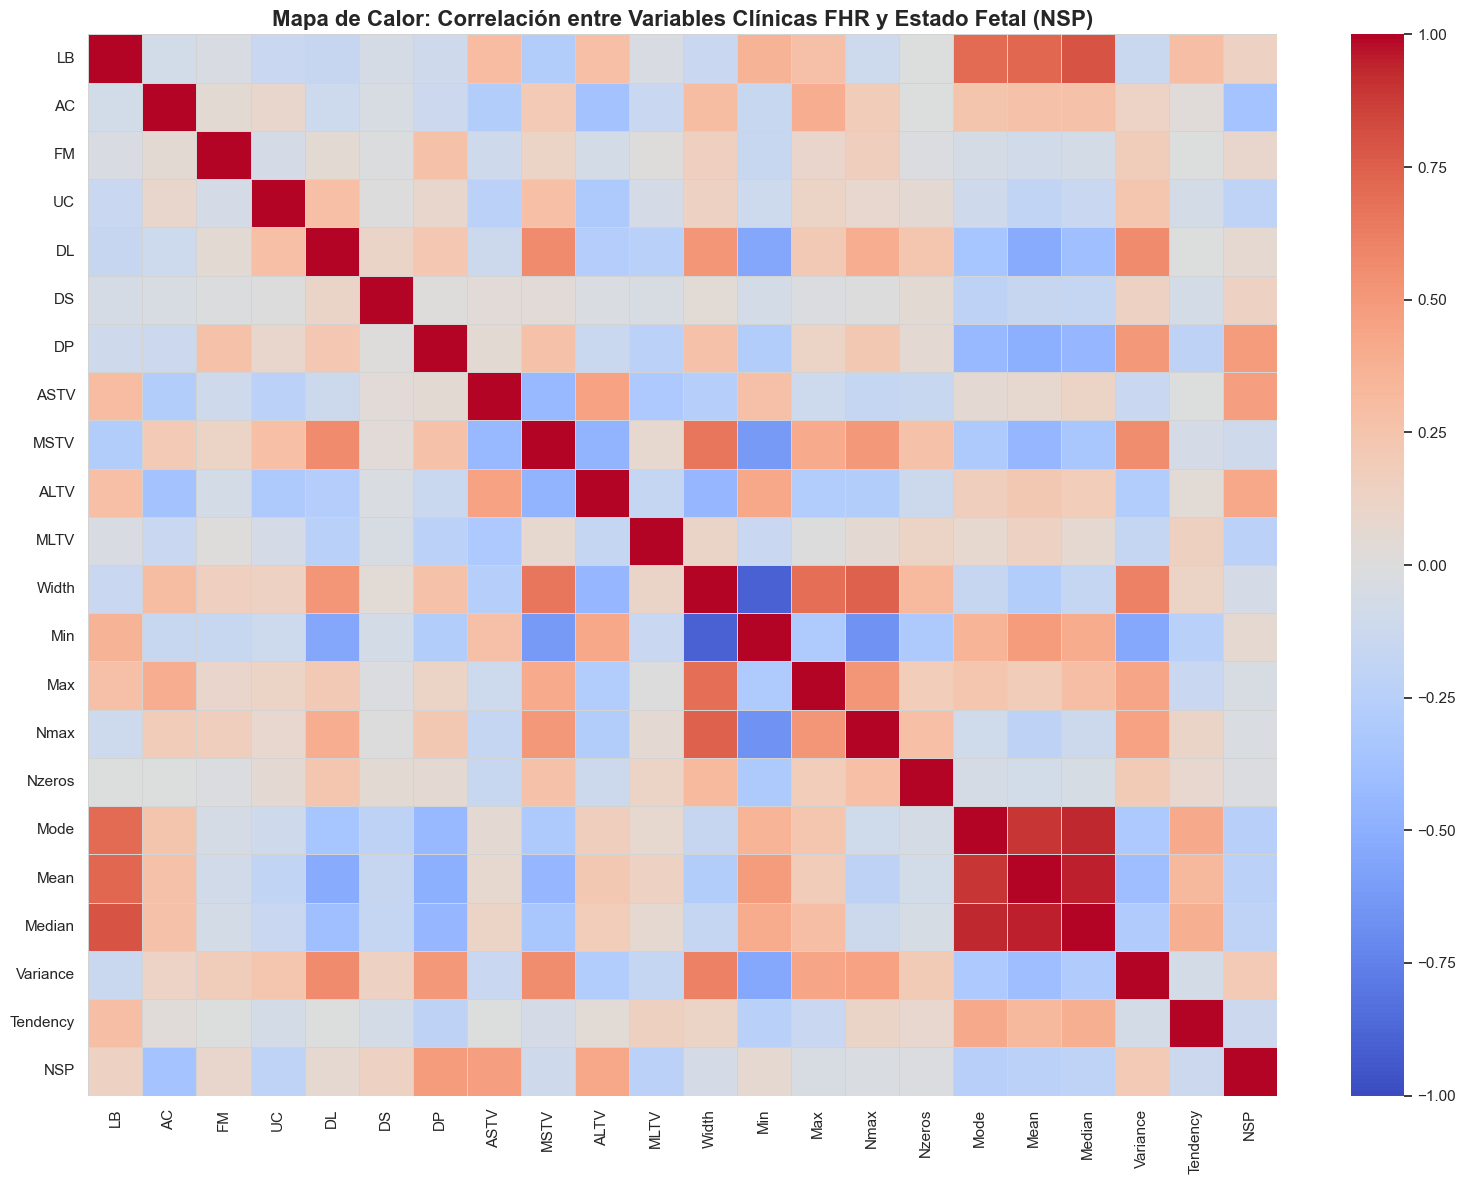

--- Top 5 Variables con mayor impacto hacia estado Patológico (Positivas) ---
DP          0.488277
ASTV        0.471191
ALTV        0.426146
Variance    0.206630
LB          0.148151
Name: NSP, dtype: float64

--- Top 3 Variables asociadas a bienestar fetal (Negativas) ---
AC     -0.363849
Mode   -0.250412
Mean   -0.226985
Name: NSP, dtype: float64


In [8]:
# HeatMap  

corr_matrix = df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(corr_matrix, 
            cmap='coolwarm', 
            vmin=-1, vmax=1, 
            linewidths=0.5, 
            linecolor='lightgrey')

plt.title('Mapa de Calor: Correlación entre Variables Clínicas FHR y Estado Fetal (NSP)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

print("--- Top 5 Variables con mayor impacto hacia estado Patológico (Positivas) ---")
print(corr_matrix['NSP'].sort_values(ascending=False)[1:6])

print("\n--- Top 3 Variables asociadas a bienestar fetal (Negativas) ---")
print(corr_matrix['NSP'].sort_values(ascending=True)[:3])


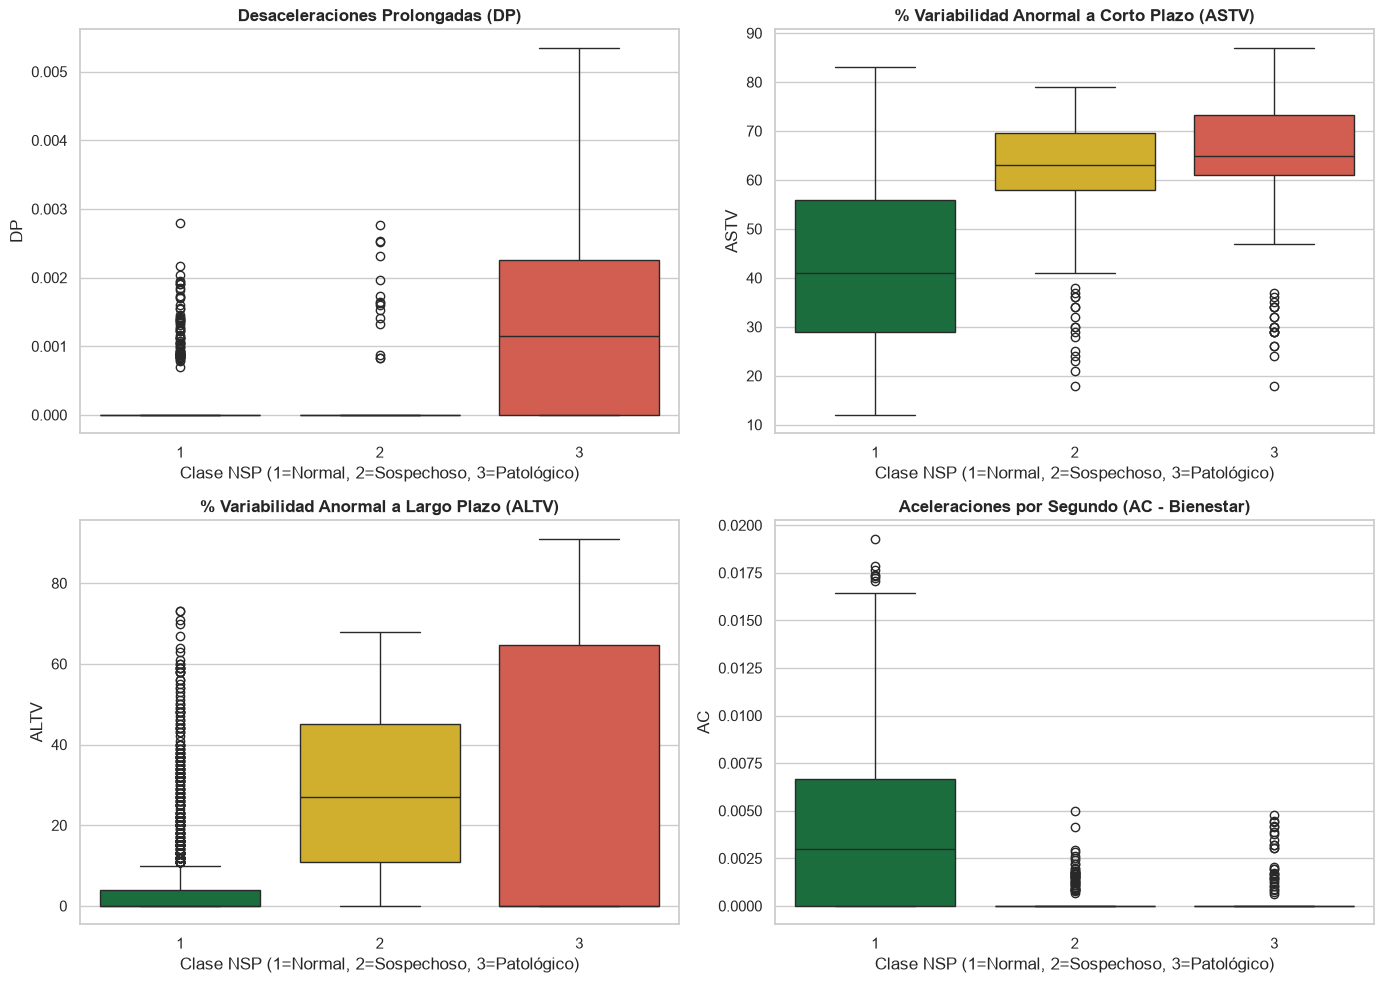

In [9]:
# Visualización de las 4 variables con mayor poder predictivo frente a NSP y análisis de Outliers

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
variables_clave = [
    ('DP', 'Desaceleraciones Prolongadas (DP)'),
    ('ASTV', '% Variabilidad Anormal a Corto Plazo (ASTV)'),
    ('ALTV', '% Variabilidad Anormal a Largo Plazo (ALTV)'),
    ('AC', 'Aceleraciones por Segundo (AC - Bienestar)')
]
colores = ["#0e7b3b", "#eabf12", "#e74c3c"]

for ax, (col, titulo) in zip(axes.flatten(), variables_clave):
    sns.boxplot(data=df, x='NSP', y=col, palette=colores, hue='NSP', ax=ax, legend=False)
    ax.set_title(f'{titulo}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Clase NSP (1=Normal, 2=Sospechoso, 3=Patológico)')
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

**Justificación de Preprocesamiento (Outliers, Variables Categóricas y Escalamiento):**

* **Conservación de Outliers:** Como se observa en los Boxplots, variables críticas como `DP` y `ALTV` concentran valores cercanos a cero en fetos sanos (Clase 1), por lo que cualquier elevación aparece como un **outlier**. En el contexto clínico de cardiotocografía, estos valores extremos no son ruido ni errores de medición, sino **indicadores fisiológicos directos de hipoxia y sufrimiento fetal (Clase 3)**. Eliminarlos destruiría la información de la clase minoritaria; por ello decidimos conservarlos.

* **Manejo de Variables Categóricas:** Todas las características predictivas de la matriz `X` son continuas o discretas numéricas (incluyendo `Tendency`, que ya posee una codificación ordinal natural de `-1, 0, 1`), por lo que no se requiere transformación adicional.

* **Criterio de Estandarización:** Aunque las escalas varían ampliamente, los algoritmos basados en particiones de árboles (*Decision Trees*, *Random Forest*, *Gradient Boosting*) evalúan umbrales por característica de forma independiente y son invariantes a la escala. La estandarización *Z-Score* se reservará exclusivamente para modelos basados en distancias o gradientes lineales (como *KNN* o *Regresión Logística*).

> **Conclusión de la Etapa 4** 

> Las correlaciones confirman la lógica médica: variables como `DP`, `ASTV` y `ALTV` son los predictores positivos más fuertes de riesgo patológico (clase 3), mientras que las aceleraciones (`AC`) son el principal indicador de bienestar (correlación negativa). También se observa multicolinealidad esperada entre las variables estadísticas del histograma (como Moda, Media y Mediana).

### 5. Definición de Matriz de Características (X) y Vector Objetivo (y)

Para conectar este análisis exploratorio con la arquitectura de ML que programaremos desde cero con ayuda del curso proporcionado por el prof. Zucco, es necesario separar el dataset en sus dos componentes fundamentales:

* **Matriz `X` (Features):** Estructura bidimensional que contendrá únicamente las 21 mediciones fisiológicas de los pacientes. Sobre esta matriz se aplicará la estandarización Z-Score.

* **Vector `y` (Target):** Estructura unidimensional que contendrá la etiqueta real del diagnóstico (`NSP`). Será nuestra base de "verdad" para comparar contra las predicciones (`y_hat`) y calcular la Matriz de Confusión.

In [9]:
# Features
X = df.drop(columns=['NSP'])

# Target
y = df['NSP']

print("--- Dimensiones Finales para Machine Learning ---")
print(f"Matriz X (Características): {X.shape} -> 2126 pacientes con 21 variables predictivas.")
print(f"Vector y (Objetivo): {y.shape} -> 2126 etiquetas diagnósticas.")

# Guardar
import os
os.makedirs('../data/processed', exist_ok=True)

X.to_csv('../data/processed/X_features.csv', index=False)
y.to_csv('../data/processed/y_target.csv', index=False)



--- Dimensiones Finales para Machine Learning ---
Matriz X (Características): (2126, 21) -> 2126 pacientes con 21 variables predictivas.
Vector y (Objetivo): (2126,) -> 2126 etiquetas diagnósticas.


> **Conclusión de la Etapa 5:** 

> El dataset ha sido exitosamente dividido en sus componentes algebraicos finales. Tenemos una matriz `X` de $(2126 \times 21)$ y un vector `y` de $(2126 \times 1)$ debidamente exportados. 